# MVP twin test: Llama 3.1 8B against the supervised models on the evaluation window

The project asks under what conditions LLM digital twins predict survey answers that depend on external state better
than supervised models do (`docs/motivation.md`). Its hypothesis is that twins predict better in a regime unlike those
the models were trained on, because a language model's general knowledge of how people respond to conditions can stand
in for training data from that regime.

A regime is the set of internal and external conditions under which people answer. The models observe only part of it,
11 respondent attributes (notebook 03) and 10 state variables (notebook 04), so each model is a function of the observed
conditions, and none can predict what a change in the unobserved ones does to answers. A supervised model's function is
fitted to the training window, which limits it in two ways. The first is coverage: observed conditions can take values
or combinations that the window lacks. The second is confounding: they can recur without the unobserved conditions that
came with them in the window, whose effects the function attributes to them. A twin's function comes from general
knowledge instead, so the hypothesis expects it to be the more accurate in both cases.

Each answer is an opinion shaped by a regime's conditions and recorded through the survey's form. A zero-shot twin
almost certainly models that form worse than supervised models (notebook 05, section 3). If this handicap is constant,
the hypothesis predicts that the twin's relative accuracy rises as the regime departs from training. The preregistration
`docs/prereg/mvp-twin.md` (OSF: https://osf.io/ahgkw) tests this prediction, with each month's state variables standing
for its regime.

The test is inconclusive: the twin's advantage does not rise with the distance in state variables, which measures a
regime only by its observed external conditions (sections 1 to 6). Sections 7 to 9 then ask the global question
directly. On answer shares, the calibrated twins given the state predict better than every supervised model on every
item, almost always beyond sampling noise, and beat the baseline shares beyond sampling noise on three or four items.
The lead comes from the state. Without the state variables, the twins and the supervised models are about level with the
baseline shares. With them, the twins move closer to the actual shares and every supervised model moves further away
(sections 7 and 8). On individual answers, only the scaled twin beats a constant prediction on every item (section 9).
Section 11 draws the conclusions.

Results are read from `experiments/mvp/2026-11-05-twin-prereg-scores/`, written by `python -m sdt.mvp.twin_score
twin-prereg-scores`, and from the two runs it scores: the twins in `2026-11-05-twin-prereg-eval/` and the supervised
models in `2026-10-26-supervised-macro-politics-ridge/`. Their per-interview files are not in git.

In [1]:
import json, warnings
warnings.filterwarnings('ignore', message='IProgress not found')        # quiet a library warning
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from scipy.stats import spearmanr
from sdt.mvp import twin
from sdt.mvp.clean import CLASSES, OUT_PATH, OUTCOMES
from sdt.mvp.encode import state_table
from sdt.mvp.primary import COMPARATORS, TWIN
from sdt.mvp.run import EXPERIMENTS
from sdt.mvp.score import PERIODS, bootstrap, draw_counts
from sdt.mvp.windows import split
from sdt.paths import DATA, RAW_CSV
pd.set_option('display.max_columns', None); pd.set_option('display.width', None)
ITEMS = list(OUTCOMES)
DMP, LOGIT = 'demographics_macro_politics', 'mnl_demographics_macro_politics'
SCALED = f'twin_scale_{DMP}'
NAMES = {TWIN: 'shifted twin', SCALED: 'scaled twin', LOGIT: 'logit', 'baseline': 'baseline shares'}
SHORT = {'demographics': 'D', 'demographics_macro': 'D+M', 'demographics_politics': 'D+P', DMP: 'D+M+P'}
SUPERVISED_MODELS = [f'{f}_{fs}' for f in ['mnl', 'ridge', 'gb'] for fs in SHORT]
month = lambda m: pd.to_datetime(pd.Series(m).astype(str), format='%Y%m')
period = lambda m: 'Baseline' if m < PERIODS['Flip'] else 'Flip' if m < PERIODS['Tariffs'] else 'Tariffs'
label = lambda m: f"{m.split('_', 1)[0]} {SHORT[m.split('_', 1)[1]]}"      # 'mnl_demographics' -> 'mnl D'
EVENTS = ['2024-11-01', '2025-02-01']          # first survey months of Flip and Tariffs, dashed in the figures

clean = pd.read_parquet(OUT_PATH)
train, test = split(clean)
key = clean.set_index('CASEID')
SCORES, TWINS = EXPERIMENTS / '2026-11-05-twin-prereg-scores', EXPERIMENTS / '2026-11-05-twin-prereg-eval'
SUPERVISED = EXPERIMENTS / '2026-10-26-supervised-macro-politics-ridge'
scores = pd.read_csv(SCORES / 'scores.csv')
cell = scores.set_index(['period', 'group', 'model', 'item']).sort_index()
allc = cell.loc[('all', 'all')]                # every model and item over all months and respondents
primary = json.load(open(SCORES / 'primary.json'))
months = pd.read_csv(SCORES / 'primary_months.csv').set_index('month')
W = pd.read_csv(SCORES / 'primary_distances.csv').pivot(index='month', columns=['model', 'item'], values='wasserstein')
by_period = pd.read_csv(SCORES / 'calibration_by_period.csv')
meta, twin_meta = json.load(open(SCORES / 'run.json')), json.load(open(TWINS / 'run.json'))
print(f"Scoring run of {meta['date']} at commit {meta['commit'][:7]}; twin run at commit {twin_meta['commit'][:7]}; "
      f"supervised run at commit {meta['sources']['supervised']['commit'][:7]}")

# Evaluation predictions of the two calibrated twins on D+M+P, the shifted twin on D and D+P, the 12 supervised models
# and the baseline shares
TWIN_MODELS = [TWIN, SCALED, 'twin_shift_demographics', 'twin_shift_demographics_politics']
pred = pd.concat([pd.read_parquet(TWINS / 'predictions.parquet', filters=[('model', 'in', TWIN_MODELS)]),
                  pd.read_parquet(SUPERVISED / 'predictions.parquet',
                                  filters=[('model', 'in', SUPERVISED_MODELS + ['baseline'])])])
pred = pred[pred.CASEID.isin(test.CASEID)].reset_index(drop=True)
answer = key.loc[pred.CASEID, ITEMS].to_numpy()[np.arange(len(pred)), pred.item.map(ITEMS.index).to_numpy()]
pred = pred.assign(**{c: key.loc[pred.CASEID, c].to_numpy() for c in ['YYYYMM', 'WT']},
                   party=key.loc[pred.CASEID, 'POLAFF'].astype(object).fillna('none').to_numpy(),
                   actual_fav=answer == 'fav', actual_unf=answer == 'unf')

def net_balance(item, models, party=None):
    """Weighted net balance, % favourable − % unfavourable, by evaluation month: actual, and predicted by each model."""
    p = pred[pred.item == item]
    if party is not None:
        p = p[p.party == party]
    nb = lambda g, f, u: 100 * np.average(g[f].astype(float) - g[u].astype(float), weights=g.WT)
    by_month = lambda m, f, u: p[p.model == m].groupby('YYYYMM').apply(nb, f, u, include_groups=False)
    return pd.DataFrame({'actual': by_month('baseline', 'actual_fav', 'actual_unf')}
                        | {m: by_month(m, 'fav', 'unf') for m in models})

def mark(model, item, score='wasserstein', group='all', period='all', fmt='+.3f'):
    """A score or difference in one cell of period and group, with * when its 95% interval excludes zero."""
    r = cell.loc[(period, group, model, item)]
    return f"{r[score]:{fmt}}{'*' if r[f'{score}_lo'] > 0 or r[f'{score}_hi'] < 0 else ''}"

Scoring run of 2026-11-05 at commit 0f6b6bc; twin run at commit e4b385b; supervised run at commit 53877d8


## 1. The plan

The plan states the hypothesis as: an LLM twin's accuracy in predicting survey answers, relative to supervised models
given the same inputs, increases as the inputs become less like those of the training data. The inputs are the 11
respondent attributes and the 10 state variables. Only the state variables describe the month, so the test registers a
new regime only through its observed external conditions. At registration, on 3 November 2026, every evaluation answer
and supervised score was known, but no twin prediction for an evaluation interview existed.

Notebook 04's four feature sets are D, the respondent attributes alone, D+M and D+P, which add the macro or the
political state variables, and D+M+P, which adds both. The primary test compares the shifted twin on D+M+P with the
multinomial logit on D+M+P and with the baseline shares. Both calibrated twins adjust the zero-shot twin's log-odds with
parameters fitted to the training window's 2,257 web interviews, the training web interviews below (notebook 05, section
3.1): the shifted twin adds a constant b to each answer's log-odds, and the scaled twin also multiplies them by a factor
a. The constant makes the shifted twin's answer shares match those of the training web interviews, as the logit's and
the baseline shares' do, so the three models start level and each misses a later month's shares only by its error in how
they moved since then. It removes the zero-shot twin's average error on those interviews and keeps every difference in
log-odds the model gives, including its response to the state.

The primary test leaves out the scaled twin because its factor a rescales the twin's response to the state by an amount
fitted within one regime. It leaves out the zero-shot twin because it starts far from the answer shares (6% unfavourable
on `BUS5` against an actual 26%; notebook 05, section 5.1), and near 6% a given move in log-odds changes the share less
than near 26%, so its gap can widen as answers move even when it moves the right way. The notebook's analyses are of
three kinds:

- **Primary:** the test on which the outcome rests (sections 3 and 4).
- **Secondary:** the analyses that the plan also lists, all reported here: the three periods, the other twins and
  supervised models, the individual score, items, parties and the two diagnostics of section 6.
- **Exploratory:** the analyses that the plan does not list, chosen with the results known: the leave-one-out values
  (section 4); the trade-policy index, the split without `DUR`, the reason and news codes, r and k, and the orderings of
  section 5; the time sibling and the redraws of section 6; and, in sections 8 and 9, the paired differences against
  every supervised model and between the two calibrations, and the net balances by party of Figure 9.

## 2. The run

The twin run used the pilot's command (notebook 05, section 4) at the commit of the preregistration tag, with the
evaluation interviews added: Llama 3.1 8B Instruct in fp32 at batch size 16, one feature set on each of four NVIDIA RTX
PRO 6000 GPUs, in about 3.5 hours (its `run.json` records GPU time summed over the four). Its probabilities for the
training web interviews reproduce the pilot's:

In [2]:
pilot = pd.read_parquet(EXPERIMENTS / '2026-10-30-twin-pilot-training-web' / 'option_probs.parquet')
raw = pd.read_parquet(TWINS / 'option_probs.parquet')
both = pilot[pilot.stage == 'base'].merge(raw[raw.interviews == 'train-web'], on=['feature_set', 'item', 'CASEID'],
                                          suffixes=('_pilot', '_eval'))
same = all(np.array_equal(both[f'{c}_pilot'], both[f'{c}_eval'], equal_nan=True) for c in twin.RAW)
print(f"{twin_meta['per_stage']['base']['prompts']:,} prompts: {twin_meta['interviews']['eval']:,} evaluation and "
      f"{twin_meta['interviews']['train-web']:,} training web interviews x 5 items x 4 feature sets")
print(f"{len(both):,} training web probabilities identical to the pilot's: {same}")

468,800 prompts: 21,183 evaluation and 2,257 training web interviews x 5 items x 4 feature sets
45,140 training web probabilities identical to the pilot's: True


`sdt.mvp.twin_score` scored the run only after checking that `data.csv`, the raw twin probabilities and the twins'
calibration match what the runs recorded, and that the supervised predictions reproduce their run's scores.

## 3. How the test works

The test correlates a dissimilarity with an advantage across the 19 evaluation months. Sections 3.1 and 3.2 trace both
on December 2024, the month farthest from the training months.

### 3.1 Dissimilarity

The dissimilarity d_t measures how far month t's state variables lie from those of the nearest training month:

1. Standardise each of the 10 state variables by its mean and standard deviation over the 90 training months, so that
   variables in different units share one scale.
2. For each evaluation month, compute the Euclidean distance to each training month.
3. Take the smallest of the 90 distances as d_t.

December 2024, and d_t for every evaluation month:

In [3]:
S = state_table(tuple(sorted(clean.YYYYMM.unique())))
tr = S.loc[sorted(train.YYYYMM.unique())]
mean, sd = tr.mean(), tr.std(ddof=0)
Z = (S - mean) / sd
gaps = lambda t: np.sqrt(((Z.loc[tr.index] - Z.loc[t]) ** 2).sum(axis=1))      # distance to every training month
assert np.allclose([gaps(t).min() for t in months.index], months.d, atol=1e-5)   # the scoring run's d_t
T = 202412
near = gaps(T).idxmin()
gap = Z.loc[T] - Z.loc[near]
print(f'{len(tr)} training months; nearest to December 2024: {near}; d_t = {np.sqrt((gap ** 2).sum()):.3f}')
display(pd.DataFrame({'December 2024': S.loc[T], f'{near} (nearest)': S.loc[near], 'training mean': mean,
                      'training SD': sd, 'gap in SDs': gap, 'squared gap': gap ** 2}).round(3),
        pd.DataFrame({'period': [period(t) for t in months.index], 'd_t': months.d.round(2),
                      'nearest training month': [gaps(t).idxmin() for t in months.index]}, index=months.index))

90 training months; nearest to December 2024: 202407; d_t = 2.182


,December 2024,202407 (nearest),training mean,training SD,gap in SDs,squared gap
cpi,2.60,3.30,3.469,2.281,-0.307,0.094
cpi_d1y,-0.60,-0.70,0.289,2.672,0.037,0.001
unrate,4.10,4.00,4.626,1.975,0.051,0.003
unrate_d1y,0.30,0.30,-0.142,2.735,0.000,0.000
gdp,2.70,2.90,2.067,3.218,-0.062,0.004
gdp_d1y,-0.50,1.20,0.180,5.563,-0.306,0.093
effr,4.58,5.33,1.994,1.826,-0.411,0.169
effr_d1y,-0.75,0.26,0.653,1.611,-0.627,0.393
pres_R,0.00,0.00,0.533,0.499,0.000,0.000
winner_R,1.00,0.00,0.511,0.500,2.000,4.002


,period,d_t,nearest training month
month,,,
202408,Baseline,0.31,202407
202409,Baseline,0.38,202407
202410,Baseline,0.69,202407
202411,Flip,0.73,202407
202412,Flip,2.18,202407
202501,Flip,2.18,202407
202502,Tariffs,1.55,201907
202503,Tariffs,1.57,201911
202504,Tariffs,1.53,201909


The election winner's party contributes 4.00 of December's 4.76 summed squared gaps. A party variable was 1 in about
half the training months, so its standard deviation is 0.5 and a change of party is a gap of 2, whereas December's
economy differed from July 2024's by less than 0.7 in every variable. d_t therefore falls into three groups, set by the
party variables: at most 0.73 until November 2024; 2.18 in December and January, the only evaluation months in which the
election winner and the sitting president differ; and 1.20 to 1.57 from February 2025.

### 3.2 Advantage

The advantage A_t measures how much closer the shifted twin comes to month t's actual answer shares than a comparator
does:

1. For each item, compute the Wasserstein distance between each model's predicted and the actual weighted answer shares
   in month t (notebook 03, section 2.2).
2. Subtract the shifted twin's distance from the comparator's.
3. Average the differences over the five items.

For December 2024:

In [4]:
d = W.loc[T].unstack('model').loc[ITEMS]
table = pd.DataFrame({NAMES[m]: d[m] for m in [TWIN, LOGIT, 'baseline']})
table['logit − twin'], table['baseline shares − twin'] = d[LOGIT] - d[TWIN], d['baseline'] - d[TWIN]
table.loc['mean over items'] = table.mean()
assert np.allclose(table.iloc[-1, -2:], months.loc[T, [f'A_{c}' for c in COMPARATORS]], atol=1e-5)   # A_t
table.round(3)

,shifted twin,logit,baseline shares,logit − twin,baseline shares − twin
item,,,,,
PAGO,0.035,0.049,0.028,0.014,-0.006
PEXP,0.037,0.058,0.042,0.022,0.005
BUS12,0.035,0.036,0.023,0.001,-0.013
BUS5,0.030,0.046,0.035,0.016,0.005
DUR,0.101,0.002,0.141,-0.099,0.040
mean over items,0.048,0.038,0.054,-0.009,0.006


The shifted twin is closer than the logit on four items but misses `DUR` by 0.101 against the logit's 0.002, so A_t
against the logit is −0.009, whereas against the baseline shares it is +0.006.

### 3.3 Statistic, interval and decision rule

The statistic is Spearman's rank correlation ρ between d_t and A_t across the 19 months, against each comparator: 1 if
A_t rises in exactly the order of d_t, and −1 if it falls in that order. Its 95% interval comes from the paired
bootstrap of notebook 03, section 2.4 (1,000 draws, seed 0), which recomputes every monthly distance, A_t and ρ on each
draw. A draw resamples whole interviews for all items and models at once, because A_t averages over items answered by
the same people; every interval in this notebook uses these draws. The months are held fixed, so an interval covers
which households were interviewed, not which months occurred.

The plan fixed the outcome: support if ρ's interval lies above 0 against both comparators, contradiction if it lies
below 0 against either, and inconclusive otherwise. Support needs both, because a twin that ignored the state could gain
on the logit, whose errors grow in unfamiliar months, but not on the baseline shares, which it would nearly copy.

## 4. Outcome

ρ against each comparator, with its interval and its range when any one month is left out:

In [5]:
rho = pd.DataFrame({NAMES[c]: {**primary['rho'][c],
                               'lowest, one month left out': months[f'rho_without_month_{c}'].min(),
                               'highest, one month left out': months[f'rho_without_month_{c}'].max()}
                    for c in COMPARATORS}).T
print(f"Outcome: {primary['outcome']}")
rho.rename(columns={'observed': 'rho', 'lo': '2.5%', 'hi': '97.5%'}).round(2)

Outcome: inconclusive


,rho,2.5%,97.5%,"lowest, one month left out","highest, one month left out"
logit,-0.01,-0.10,0.10,-0.11,0.16
baseline shares,0.05,-0.12,0.42,-0.10,0.13


The outcome is inconclusive: both intervals include zero. Against the logit, ρ is −0.01 with an interval from −0.10 to
0.10, which rules out all but a weak association in either direction. Against the baseline shares, ρ is 0.05 with an
interval from −0.12 to 0.42, wider because the twin's monthly distances differ little from the baseline shares', so
sampling noise reorders the months easily. Leaving out any one month keeps ρ between −0.11 and 0.16.

## 5. Why the months came out this way

Section 4 ends the confirmatory test. This section explains its result. Figure 1 adds to d_t and A_t an index of
trade-policy uncertainty, a measure of one condition that the models do not observe: the trade-policy component of
Baker, Bloom and Davis's economic policy uncertainty index, built from the share of newspaper articles that discuss
both.

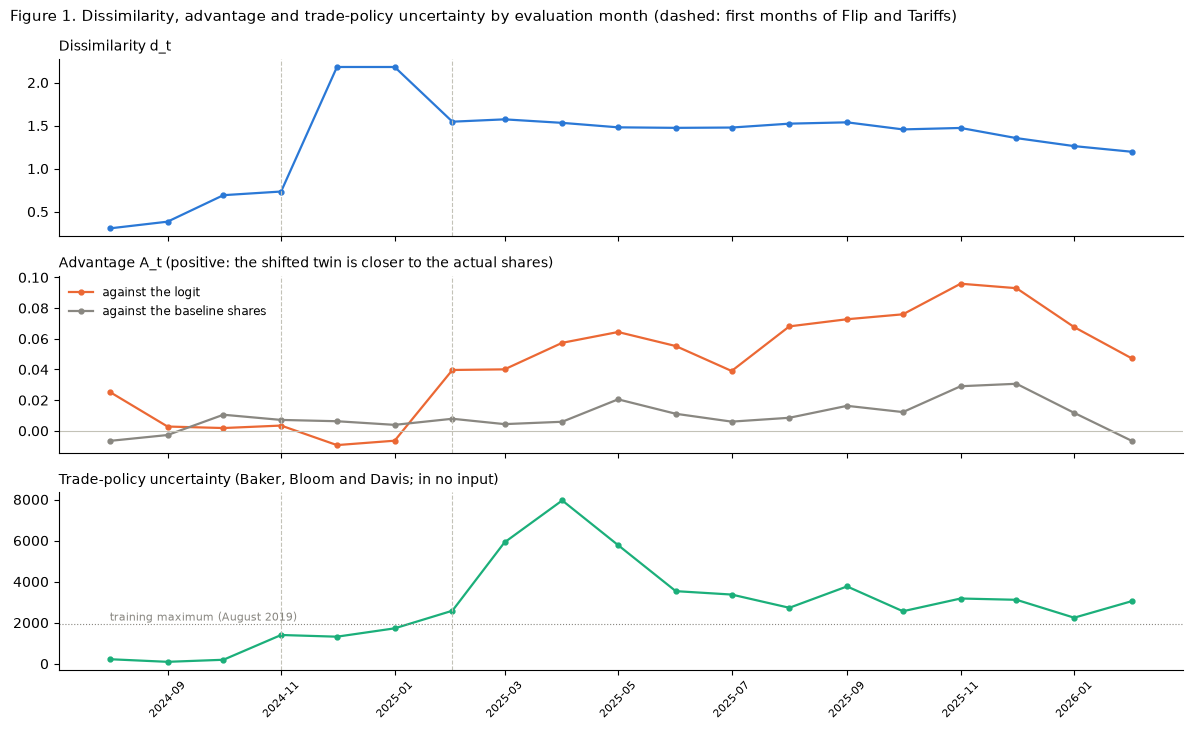

In [6]:
epu = pd.read_csv(DATA / 'external' / 'fred' / 'EPUTRADE.csv', parse_dates=['observation_date'])
epu = pd.Series(epu.EPUTRADE.to_numpy(), index=epu.observation_date.dt.year * 100 + epu.observation_date.dt.month)
epu_max = epu.loc[sorted(train.YYYYMM.unique())]
x = month(months.index)
fig, axes = plt.subplots(3, 1, figsize=(12, 7.4), sharex=True)
axes[0].plot(x, months.d.values, color='#2a78d6', lw=1.6, marker='o', ms=3.5)
for c, color in zip(COMPARATORS, ['#eb6834', '#898781']):
    axes[1].plot(x, months[f'A_{c}'].values, color=color, lw=1.6, marker='o', ms=3.5, label=f'against the {NAMES[c]}')
axes[1].axhline(0, color='#c3c2b7', lw=0.8); axes[1].legend(frameon=False, fontsize=8.5, loc='upper left')
axes[2].plot(x, epu.loc[months.index].values, color='#1baf7a', lw=1.6, marker='o', ms=3.5)
axes[2].axhline(epu_max.max(), color='#898781', lw=0.8, ls=':')
axes[2].text(x.iloc[0], epu_max.max() * 1.08, f'training maximum ({month([epu_max.idxmax()]).iloc[0]:%B %Y})',
             fontsize=8, color='#898781')
for ax, title in zip(axes, ['Dissimilarity d_t',
                            'Advantage A_t (positive: the shifted twin is closer to the actual shares)',
                            'Trade-policy uncertainty (Baker, Bloom and Davis; in no input)']):
    for d in EVENTS:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.set_title(title, loc='left', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
axes[2].tick_params(axis='x', labelsize=8, rotation=45)
fig.suptitle('Figure 1. Dissimilarity, advantage and trade-policy uncertainty by evaluation month '
             '(dashed: first months of Flip and Tariffs)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

Against the logit, the shifted twin does worst in December and January, the two months of highest d_t, and best late in
2025, at middling d_t. Against the baseline shares, its lead is small throughout and largest late in 2025. Sections 5.1
and 5.2 explain the two episodes, and section 5.3 what d_t measured.

### 5.1 December and January

Figure 2 shows the net balance, the favourable share minus the unfavourable share, of three items, actual and predicted:

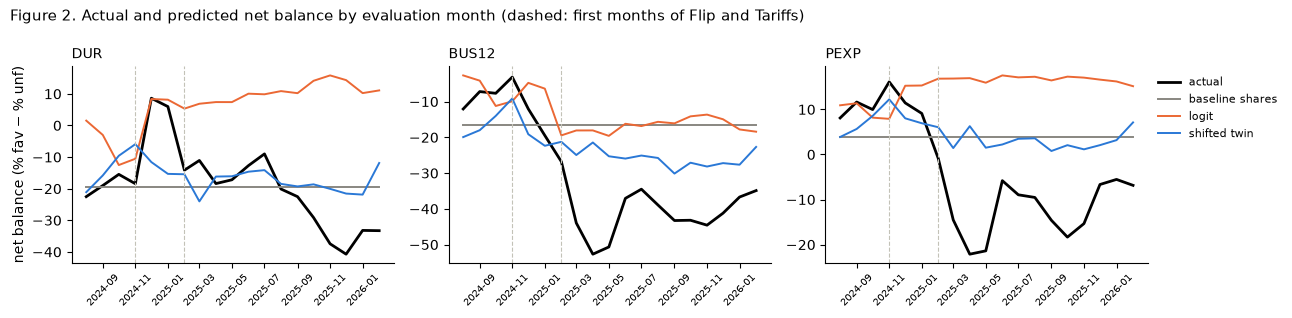

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, item in zip(axes, ['DUR', 'BUS12', 'PEXP']):
    nb = net_balance(item, ['baseline', LOGIT, TWIN])
    ax.plot(month(nb.index), nb.actual.values, color='black', lw=2, label='actual')
    for m, color in [('baseline', '#898781'), (LOGIT, '#eb6834'), (TWIN, '#2a78d6')]:
        ax.plot(month(nb.index), nb[m].values, color=color, lw=1.4, label=NAMES[m])
    for d in EVENTS:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.set_title(item, loc='left', fontsize=10); ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('net balance (% fav − % unf)')
axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 2. Actual and predicted net balance by evaluation month (dashed: first months of Flip and Tariffs)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

The table splits A_t against the logit by item for August 2024 to January 2025, and gives A_t without `DUR` against both
comparators (`DUR` was singled out after seeing the result):

In [8]:
rest = ITEMS[:4]                                                       # every item but DUR
lead = lambda c, items: W[c][items] - W[TWIN][items]                   # comparator's monthly distance minus the twin's
t = lead(LOGIT, ITEMS).loc[:202501]
t['A_t'] = t.mean(axis=1)
assert np.allclose(t.A_t, months.loc[:202501, f'A_{LOGIT}'], atol=1e-5)
t['A_t without DUR'] = lead(LOGIT, rest).loc[:202501].mean(axis=1)
t['A_t without DUR, against the baseline shares'] = lead('baseline', rest).loc[:202501].mean(axis=1)
without = {NAMES[c]: spearmanr(months.d, lead(c, rest).mean(axis=1))[0] for c in COMPARATORS}
print('rho without DUR: ' + ', '.join(f'{v:.2f} against the {k}' for k, v in without.items()))
t.round(3)

rho without DUR: 0.28 against the logit, -0.13 against the baseline shares


item,PAGO,PEXP,BUS12,BUS5,DUR,A_t,A_t without DUR,"A_t without DUR, against the baseline shares"
month,,,,,,,,
202408,0.053,-0.007,0.008,-0.040,0.113,0.025,0.003,-0.010
202409,0.033,-0.029,-0.039,-0.016,0.064,0.003,-0.012,-0.000
202410,0.011,0.002,-0.002,0.012,-0.015,0.002,0.006,0.015
202411,0.004,0.021,0.004,0.011,-0.023,0.003,0.010,0.023
202412,0.014,0.022,0.001,0.016,-0.099,-0.009,0.013,-0.002
202501,-0.015,0.021,0.049,0.008,-0.095,-0.006,0.016,-0.000


The negative A_t against the logit comes from `DUR`. Without it, the twin led the logit by 0.013 in December and 0.016
in January, more than in any earlier month, but led the baseline shares by about zero, less than in October and
November. Where d_t was highest, the twin thus gained only where the logit erred. Without `DUR`, ρ would be 0.28 against
the logit and −0.13 against the baseline shares, so the outcome would stand.

On `DUR`, the actual net balance jumped from −18 in November to +9 in December, and the logit's prediction jumped from
−11 to +8, because `winner_R` turned to 1 and its coefficient carries the high `DUR` answers of the first Trump
presidency (notebook 04, section 5.3). The logit then stayed between +5 and +16 while answers fell to −41, so its
December hit came from the confound. The reasons respondents gave and the news they had heard show what moved the
answers:

In [9]:
# Codebook labels (data/DDI XML.txt): DURRN 13 "FAV Prices are going up, future uncertainty", 19 "FAV Low taxes, tax
# changes"; NEWS 56 "UNFAV Taxes, changes/reforms". Each question records up to two mentions.
codes = pd.read_csv(RAW_CSV, skipinitialspace=True, usecols=['CASEID', 'DURRN1', 'DURRN2', 'NEWS1', 'NEWS2'])
c = clean.merge(codes, on='CASEID')

def mention(d, cols, values):
    """Weighted share of each month's interviews of `d` that give any of `values` in any of `cols`."""
    w = d.WT.where(d[cols].isin(values).any(axis=1), 0)
    return w.groupby(d.YYYYMM).sum() / d.WT.groupby(d.YYYYMM).sum()

shares = pd.DataFrame({'good time to buy: prices going up or tax changes (DUR, of those answering)':
                           mention(c[c.DUR.notna()], ['DURRN1', 'DURRN2'], [13, 19]),
                       'heard unfavourable news about taxes (of all)': mention(c, ['NEWS1', 'NEWS2'], [56])})
show = shares.loc[202408:202503].rename(index=str)
show.loc['Jul 2018 to Dec 2019, mean'] = shares.loc[201807:201912].mean()
show.loc['Feb 2021 to Jul 2024, highest month'] = shares.loc[202102:202407].max()
(100 * show).round(0).astype(int)

,"good time to buy: prices going up or tax changes (DUR, of those answering)",heard unfavourable news about taxes (of all)
YYYYMM,,
202408,6,2
202409,6,1
202410,9,1
202411,10,3
202412,24,12
202501,26,13
202502,23,24
202503,24,28
"Jul 2018 to Dec 2019, mean",15,17


Among `DUR` respondents, the share who called it a good time to buy because prices are going up or taxes are changing
rose from 10% in November to 24% in December and 26% in January, above any month from 2021 to mid-2024. The share who
had heard unfavourable news about taxes rose from 3% to 12% and 13%, against at most 8% from 2021 to mid-2024 and a mean
of 17% in the trade war of 2018 and 2019 (both earlier periods are mostly phone interviews). The code list has no tariff
code, tariffs are taxes on imports, and trade-policy uncertainty rose sevenfold from October to November, so respondents
were most likely buying ahead of tariffs, an unobserved condition.

Figure 3 shows the partisan reversal in the net balance of `PEXP`, whether the family will be better off a year from
now, by party:

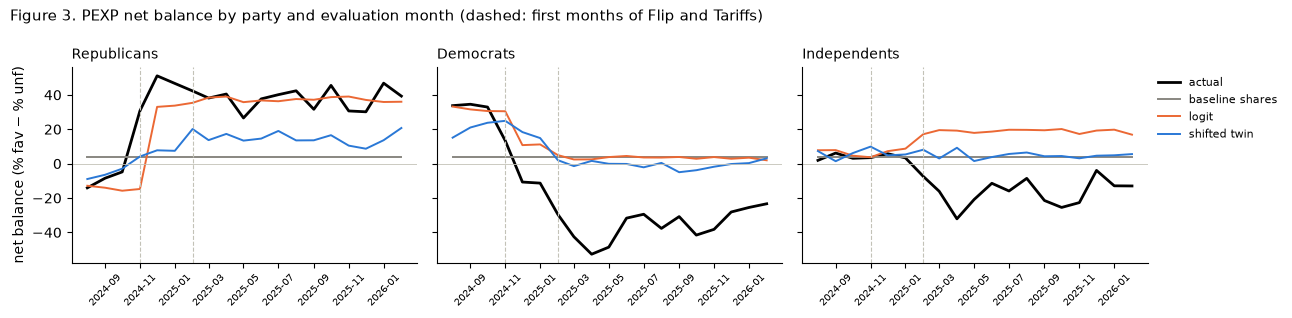

Republican minus Democratic net balance, mean over the tariff months: actual 73, mnl_demographics_macro_politics 34, twin_shift_demographics_macro_politics 16


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
gap = {}
for ax, party in zip(axes, ['Rep', 'Dem', 'Ind']):
    nb = net_balance('PEXP', ['baseline', LOGIT, TWIN], party)
    gap[party] = nb.loc[PERIODS['Tariffs']:]
    ax.plot(month(nb.index), nb.actual.values, color='black', lw=2, label='actual')
    for m, color in [('baseline', '#898781'), (LOGIT, '#eb6834'), (TWIN, '#2a78d6')]:
        ax.plot(month(nb.index), nb[m].values, color=color, lw=1.4, label=NAMES[m])
    for d in EVENTS:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.axhline(0, color='#c3c2b7', lw=0.6)
    ax.set_title({'Rep': 'Republicans', 'Dem': 'Democrats', 'Ind': 'Independents'}[party], loc='left', fontsize=10)
    ax.tick_params(axis='x', labelsize=7, rotation=45); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('net balance (% fav − % unf)')
axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 3. PEXP net balance by party and evaluation month (dashed: first months of Flip and Tariffs)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()
print('Republican minus Democratic net balance, mean over the tariff months: ' +
      ', '.join(f'{k} {(gap["Rep"][k] - gap["Dem"][k]).mean():.0f}' for k in ['actual', LOGIT, TWIN]))

Respondents reversed at the election, inside the November window, and the logit in December, when `winner_R` turned to
1, as it had learned from its one precedent, December 2020 and January 2021. The shifted twin kept Democrats above
Republicans until the president changed in February 2025, and over the tariff months separated the parties by 16 points,
against 73 for respondents and 34 for the logit. It responds to the sitting president rather than the election winner.
Neither calibration can repair that, because b leaves differences between respondents unchanged and a only scales them.
In the shares of all respondents the parties' errors largely cancel, so A_t does not show them.

December and January thus show two things. A_t against the logit turned negative through one item, on which the logit
was right for an unrelated reason. And the twin did not reverse the parties when the election winner changed, the change
that made these months the most unusual by d_t.

### 5.2 The tariff months

From February 2025, answers collapsed: the net balance of `BUS12` fell from −27 to −53 by April. The economic variables
stayed inside their training ranges (notebook 04, section 1), and the party variables say only that a Republican
governs, so the change lay mostly in unobserved conditions. The first table gives each model's mean distance by period,
with the mean d_t and A_t. The second measures how each model's monthly net balance moves with the actual one over the
19 months: r, their correlation, says whether the model moves in the right direction, and k, the ratio of their standard
deviations, says how much it moves.

In [11]:
by = lambda s: s.groupby(s.index.map(period)).mean().loc[list(PERIODS)]
display(pd.DataFrame({'d_t': by(months.d),
                      **{f'distance, {NAMES[m]}': by(W[m].mean(axis=1)) for m in ['baseline', LOGIT, TWIN]},
                      **{f'A_t against the {NAMES[c]}': by(months[f'A_{c}']) for c in COMPARATORS}}).round(3))

# How each model's monthly net balance moves with the actual one over the 19 months: r, the correlation, says whether
# it moves in the right direction; k, the ratio of the two standard deviations, says how far it moves.
move = {}
for item in ITEMS:
    nb = net_balance(item, [TWIN, SCALED, LOGIT])
    for m in [TWIN, SCALED, LOGIT]:
        move[NAMES[m], 'r', item] = nb[m].corr(nb.actual)
        move[NAMES[m], 'k', item] = nb[m].std() / nb.actual.std()
move = pd.Series(move).unstack([0, 1]).loc[ITEMS]
move[[NAMES[TWIN], NAMES[LOGIT]]].round(2)

,d_t,"distance, baseline shares","distance, logit","distance, shifted twin",A_t against the logit,A_t against the baseline shares
month,,,,,,
Baseline,0.461,0.024,0.033,0.023,0.010,0.000
Flip,1.699,0.050,0.040,0.044,-0.004,0.006
Tariffs,1.453,0.079,0.130,0.067,0.063,0.012


shifted twin       logit      
                 r     k     r     k
PAGO          0.59  0.79  0.33  0.48
PEXP          0.73  0.25 -0.75  0.25
BUS12         0.82  0.33  0.78  0.35
BUS5          0.77  0.46 -0.26  0.05
DUR           0.39  0.36 -0.26  0.60

No model anticipated the collapse, but the logit missed the tariff months by most, because it moved the wrong way: with
a Republican president it predicted the optimism of the first Trump presidency, a `PEXP` net balance of +15 to +18
against an actual −22 to −1. Figure 3 locates the error among independents, who have no party product (the logit's terms
for a respondent's party times the president's, notebook 04, section 2): the logit's `PEXP` prediction for them rose
from 9 to 17 when `pres_R` turned to 1, while their answers fell to −32 by April.

The shifted twin moved the right way on every item, with r of 0.39 to 0.82, whereas the logit's r is negative on `PEXP`,
`BUS5` and `DUR`. But the twin moved a quarter to a half as much as the answers, with k of 0.25 to 0.46 on every item
except `PAGO`. Its lead over the logit in 2025 thus comes mostly from the logit's error, and its smaller lead over the
baseline shares from moving the right way.

### 5.3 What d_t measured

d_t measures how far a month departs from training only in its observed external conditions, and two of its properties
explain the outcome.

**It counted changes of party far above changes in the economy,** so it fell into three groups (section 3.1), and the
months make up closer to three episodes than to 19.

**It cannot see unobserved conditions, which moved answers most.** The table correlates three orderings of the months
with A_t and with how far answers moved from the training shares, measured by the baseline shares' monthly distance:

In [12]:
orders = {'d_t': months.d, 'elapsed months': months.elapsed_months, 'trade-policy uncertainty': epu.loc[months.index]}
targets = {'how far answers moved': W['baseline'].mean(axis=1),
           **{f'A_t against the {NAMES[c]}': months[f'A_{c}'] for c in COMPARATORS}}
tariff_epu = epu.loc[PERIODS['Tariffs']:months.index[-1]]
print(f'Trade-policy uncertainty: training maximum {epu_max.max():,.0f} ({epu_max.idxmax()}); '
      f'{tariff_epu.min():,.0f} to {tariff_epu.max():,.0f} in the tariff months')
pd.DataFrame({t: {o: spearmanr(x, y)[0] for o, x in orders.items()} for t, y in targets.items()}).round(2)

Trade-policy uncertainty: training maximum 1,947 (201908); 2,244 to 7,956 in the tariff months


,how far answers moved,A_t against the logit,A_t against the baseline shares
d_t,0.31,-0.01,0.05
elapsed months,0.71,0.80,0.49
trade-policy uncertainty,0.82,0.58,0.29


How far answers moved correlates 0.31 with d_t, 0.71 with elapsed months and 0.82 with trade-policy uncertainty, which
exceeded its training maximum of 1,947 (August 2019) in every tariff month, at 2,244 to 7,956. d_t placed the tariff
months nearest to July 2019 to March 2020, in the earlier trade war, because the observed states were alike; their
trade-policy uncertainty was not.

Ordering the months by trade-policy uncertainty instead does not restore the predicted trend against both comparators:
A_t correlates 0.58 with the index against the logit, whose error grew as 2025 departed from the first Trump presidency,
but only 0.29 against the baseline shares, because the twin cannot respond to unobserved conditions either.

Ordering the months by the plan's periods gives the predicted trend: A_t against the baseline shares averages 0.000 in
Baseline, 0.006 in Flip and 0.012 in Tariffs. But the periods also follow elapsed time (section 6.1).

The test thus asked whether the twin gains where the observed state is least familiar, and here it does not. It could
not ask whether the twin gains where the regime is least familiar, because the change of 2025 lay mostly in unobserved
conditions.

## 6. Diagnostics

### 6.1 Dissimilarity against elapsed time

The plan's first diagnostic is the Spearman correlation of d_t with elapsed months. Its time sibling replaces d_t with
elapsed months in the statistic, with the same draws:

In [13]:
print(f"Spearman correlation of d_t with elapsed months: {primary['spearman_d_elapsed_months']:.2f}")
pd.DataFrame({NAMES[c]: primary['rho_time'][c] for c in COMPARATORS}).T.rename(
    columns={'observed': 'rho with elapsed months', 'lo': '2.5%', 'hi': '97.5%'}).round(2)

Spearman correlation of d_t with elapsed months: 0.06


,rho with elapsed months,2.5%,97.5%
logit,0.80,0.74,0.85
baseline shares,0.49,0.19,0.65


d_t and elapsed months are nearly uncorrelated (0.06), so the two statistics order the months almost independently. A_t
rises with elapsed time against both comparators, with intervals above zero. Elapsed time orders the tariffs with every
other change of 2025, so it says when the twin gained, and section 5.2 says why.

### 6.2 Calibration across periods

The plan's second diagnostic refits both calibrations on each period's interviews, from the zero-shot twin's
probabilities on D+M+P, to show how far the training fit lies from each period's best fit. The training fit's 95% range
comes from 200 redraws of its 2,200 interviews within months; the period fits rest on 3,000 to 15,000.

In [14]:
z = pd.read_parquet(TWINS / 'predictions.parquet', filters=[('model', '==', f'twin_{DMP}')])
z = z[z.CASEID.isin(train[train.web == 1].CASEID)].join(key[['YYYYMM', 'WT'] + ITEMS], on='CASEID')
rng, redrawn = np.random.default_rng(0), []
for item, g in z.groupby('item'):
    g = g.reset_index(drop=True)
    within = [np.flatnonzero(g.YYYYMM.to_numpy() == m) for m in g.YYYYMM.unique()]
    for _ in range(200):
        r = g.iloc[np.concatenate([rng.choice(ix, len(ix)) for ix in within])]
        for name, scale in [('shift', False), ('scale', True)]:
            fit = twin.fit_calibration(r[CLASSES], r[item].astype(str), r.WT, scale)
            redrawn.append({'item': item, 'calibration': name, 'a': fit['a'], 'b_fav': fit['fav'], 'b_unf': fit['unf']})
redrawn = pd.DataFrame(redrawn)
p = by_period[by_period.feature_set == DMP]
out = {}
for param, name, row in [('a', 'scale', 'a (scaled twin)'), ('b_fav', 'shift', 'b_fav (shifted twin)'),
                           ('b_unf', 'shift', 'b_unf (shifted twin)')]:
    fit = p[p.calibration == name].pivot(index='item', columns='fitted_on', values=param)
    for item in ITEMS:
        lo, hi = np.percentile(redrawn[(redrawn.calibration == name) & (redrawn.item == item)][param], [2.5, 97.5])
        out[(row, item)] = {'training web': f"{fit.loc[item, 'training web']:.2f}",
                            'its 95% range': f'[{lo:.2f}, {hi:.2f}]', **{q: f'{fit.loc[item, q]:.2f}' for q in PERIODS}}
pd.DataFrame(out).T

training web  its 95% range Baseline  Flip Tariffs
a (scaled twin)      PAGO          0.46   [0.37, 0.53]     0.39  0.38    0.35
                     PEXP          0.30   [0.21, 0.41]     0.34  0.11    0.21
                     BUS12         0.61   [0.47, 0.76]     0.67  0.07    0.34
                     BUS5          0.31   [0.22, 0.42]     0.35  0.00    0.47
                     DUR           0.95   [0.62, 1.32]     1.04  0.70    0.52
b_fav (shifted twin) PAGO          0.69   [0.54, 0.82]     0.69  0.53    0.49
                     PEXP          1.23   [1.09, 1.36]     1.30  1.51    1.36
                     BUS12         0.59   [0.48, 0.73]     0.74  0.80    1.14
                     BUS5          1.20   [1.06, 1.33]     1.46  1.63    1.91
                     DUR          -0.39  [-0.81, 0.17]    -0.08  0.20    0.03
b_unf (shifted twin) PAGO          1.55   [1.41, 1.70]     1.53  1.19    1.28
                     PEXP          1.00   [0.89, 1.16]     0.88  1.18    1.76
                     BUS12         0.93   [0.82, 1.07]     0.70  0.89    1.78
                     BUS5          2.06   [1.91, 2.20]     1.90  2.28    2.98
                     DUR           0.38  [-0.05, 0.94]     0.76  0.75    0.90

Two changes lie well outside that range. In Flip, the scale a falls to 0.00 to 0.11 on `PEXP`, `BUS12` and `BUS5`, so
the best fit nearly ignores the twin's differences between respondents, as its reversed partisan ordering implies. In
Tariffs, b_unf rises by 0.8 to 0.9 on the same items, because respondents chose the unfavourable answer more often than
the twin predicted. Because a refitted constant also absorbs the twin's errors about opinions, neither change shows
whether the survey's form changed.

## 7. All models

Sections 7 to 9 ask the global question directly: over the 19 evaluation months, which model predicts best? Figure 4
extends notebook 04's Figure 2 with the 12 twins, named by calibration (`twin` for the zero-shot twin, `twin_shift` for
the shifted twin and `twin_scale` for the scaled twin) and by feature set:

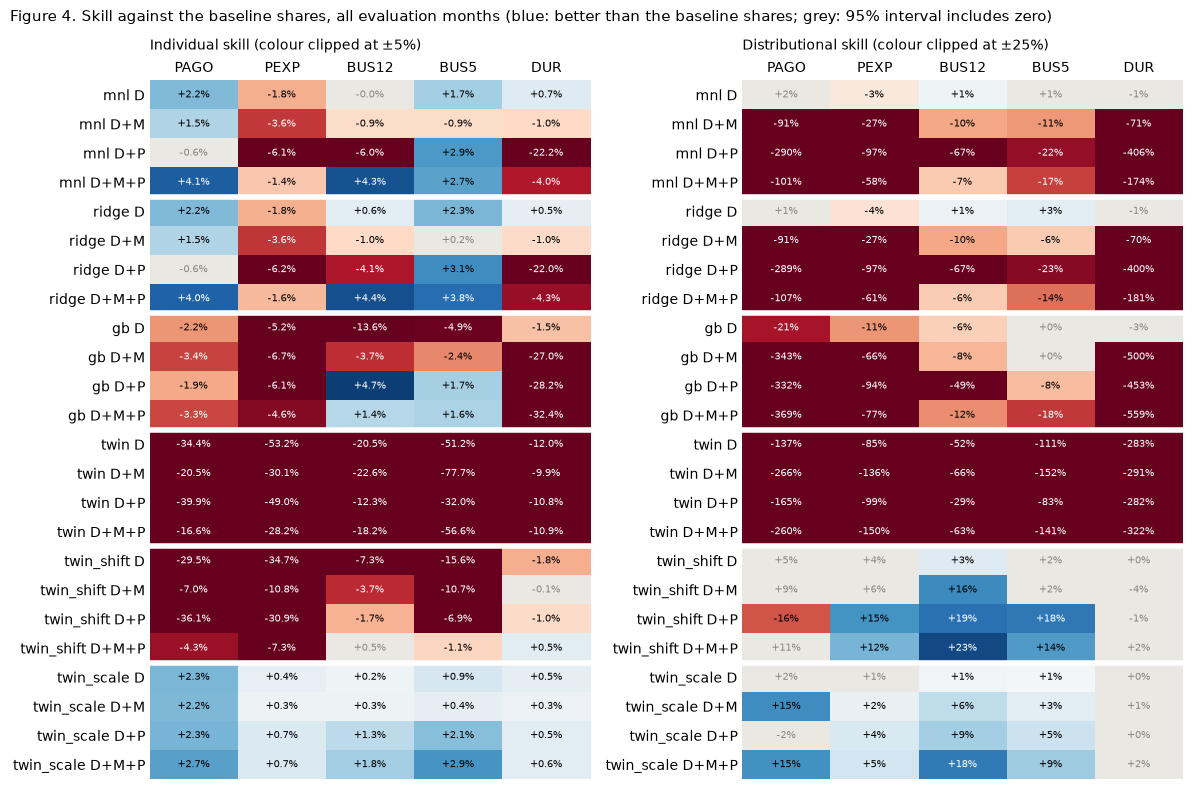

Cells whose skill interval lies above / below zero:
  zero-shot twins (20 cells): distributional 0 / 20, individual 0 / 20
  shifted twins (20 cells): distributional 8 / 1, individual 1 / 17
  scaled twins (20 cells): distributional 13 / 0, individual 20 / 0
  supervised models (60 cells): distributional 3 / 49, individual 21 / 35
log_loss: supervised skill bounds moved by up to 0.2 points from notebook 04; cells whose interval changed sides of zero: 0
wasserstein: supervised skill bounds moved by up to 5.8 points from notebook 04; cells whose interval changed sides of zero: 0


In [15]:
def heat(ax, M, vmax, fmt, cmap, grey=None):
    """Annotated heatmap with colour clipped at ±vmax; cells where `grey` is True are drawn grey."""
    rgba = plt.get_cmap(cmap)((np.clip(M, -vmax, vmax) + vmax) / (2 * vmax))
    if grey is not None:
        rgba[grey] = to_rgba('#e9e8e3')
    ax.imshow(rgba, aspect='auto')
    for (r, c), v in np.ndenumerate(M):
        g = grey is not None and grey[r, c]
        ax.text(c, r, fmt.format(v), ha='center', va='center', fontsize=7.5,
                color='#898781' if g else 'white' if abs(np.clip(v, -vmax, vmax)) > 0.65 * vmax else 'black')
    ax.tick_params(length=0); ax.spines[:].set_visible(False); ax.xaxis.tick_top()

rows = [(f, fs) for f in ['mnl', 'ridge', 'gb', 'twin', 'twin_shift', 'twin_scale'] for fs in SHORT]
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
for ax, (s, title, vmax, fmt) in zip(axes, [('log_loss_skill', 'Individual skill', 0.05, '{:+.1%}'),
                                            ('wasserstein_skill', 'Distributional skill', 0.25, '{:+.0%}')]):
    grid = lambda col: np.array([[allc.loc[(f'{f}_{fs}', i), col] for i in ITEMS] for f, fs in rows])
    heat(ax, grid(s), vmax, fmt, 'RdBu', grey=(grid(f'{s}_lo') <= 0) & (grid(f'{s}_hi') >= 0))
    ax.set_xticks(range(len(ITEMS)), ITEMS); ax.set_yticks(range(len(rows)), [f'{f} {SHORT[fs]}' for f, fs in rows])
    for y in np.arange(3.5, len(rows) - 1, 4):
        ax.axhline(y, color='white', lw=4)
    ax.set_title(f'{title} (colour clipped at ±{vmax:.0%})', loc='left', fontsize=10, pad=22)
fig.suptitle('Figure 4. Skill against the baseline shares, all evaluation months (blue: better than the baseline shares; '
             'grey: 95% interval includes zero)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

groups = {'zero-shot twins': [f'twin_{fs}' for fs in SHORT], 'shifted twins': [f'twin_shift_{fs}' for fs in SHORT],
          'scaled twins': [f'twin_scale_{fs}' for fs in SHORT], 'supervised models': SUPERVISED_MODELS}
print('Cells whose skill interval lies above / below zero:')
for name, models_ in groups.items():
    x = allc.loc[models_]
    print(f'  {name} ({len(x)} cells): distributional {(x.wasserstein_skill_lo > 0).sum()} / '
          f'{(x.wasserstein_skill_hi < 0).sum()}, individual {(x.log_loss_skill_lo > 0).sum()} / {(x.log_loss_skill_hi < 0).sum()}')
old = pd.read_csv(SUPERVISED / 'scores.csv').query("period == 'all' and group == 'all'").set_index(['model', 'item'])
old = old[old.log_loss_skill.notna()]
new = allc.loc[old.index]
for s in ['log_loss', 'wasserstein']:
    b = [f'{s}_skill_lo', f'{s}_skill_hi']
    flips = (((old[b[0]] > 0) | (old[b[1]] < 0)) != ((new[b[0]] > 0) | (new[b[1]] < 0))).sum()
    print(f'{s}: supervised skill bounds moved by up to {100 * (new[b] - old[b]).abs().max().max():.1f} points '
          f'from notebook 04; cells whose interval changed sides of zero: {flips}')

On answer shares, the calibrated twins often beat the baseline shares and almost never lose to them, whereas the
supervised models almost never beat them and usually lose. By intervals that exclude zero, the calibrated twins beat the
baseline shares in 21 of their 40 cells and lose in 1; the supervised models beat them in 3 of their 60 cells and lose
in 49.

On individual answers, only the scaled twins beat the baseline shares consistently. They beat them in all 20 of their
cells, whereas the shifted twins beat them in 1 and lose in 17, and the supervised models beat them in 21 of their 60
cells and lose in 35.

Of the three twins, the zero-shot twin loses to the baseline shares in every cell on both scores, because it starts far
from the answer shares (section 1), so calibration is what makes the twin competitive. Between the two calibrations, the
scaled twin is the stronger on individual answers, where it beats the baseline shares in 20 cells against the shifted
twin's 1. On answer shares the two are closer: the scaled twin clears the baseline shares in more cells, 13 against 8,
but on D+M+P the shifted twin comes closer to the actual shares on three items (section 9.2).

Because notebook 04 drew each item separately, its supervised skill bounds differ from these by up to 5.8 points, though
no interval changes sides of zero.

## 8. Calibrated twins against supervised models on answer shares

Figure 4 singles out the calibrated twins on answer shares. This section compares the two twins on D+M+P with every
supervised model and with the baseline shares, then traces the comparison to the state variables: overall (8.1), by
period (8.2) and by party (8.3). Figure 5 places every model's distance from the actual answer shares on one line per
item, together with the band from the noise floor, the distance that a model knowing each month's true shares would
still have (notebook 03, section 2.3), to the baseline shares:

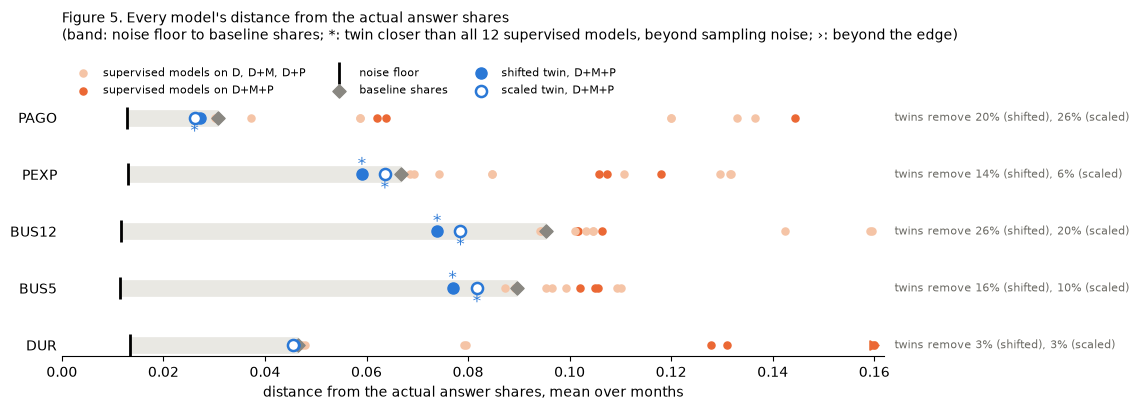

In [16]:
CAL = [TWIN, SCALED]
draws = draw_counts(test, 1000, 0)               # the scoring run's draws (N_BOOT and SEED in sdt.mvp.twin_score)
extra = bootstrap(pred[pred.model.isin(CAL + SUPERVISED_MODELS + ['baseline'])], test,
                  pairs=[(t, s) for t in CAL for s in SUPERVISED_MODELS] + [(TWIN, SCALED)],
                  draws=draws).set_index(['model', 'item'])
bounds = extra.loc[[f'{TWIN}-{LOGIT}', f'{SCALED}-{LOGIT}'], ['wasserstein_lo', 'wasserstein_hi', 'log_loss_lo', 'log_loss_hi']]
assert np.allclose(bounds, allc.loc[bounds.index, bounds.columns], atol=1e-6)       # the scoring run's intervals
beats = lambda t, s, i: extra.loc[(f'{t}-{s}', i), 'wasserstein_hi'] < 0           # t closer than s beyond noise

dist = lambda m: allc.xs(m, level='model').wasserstein.loc[ITEMS]
floor, base = dist('floor'), dist('baseline')
same = [f'{f}_{DMP}' for f in ['mnl', 'ridge', 'gb']]
# Claim check: each twin beats each supervised model on D+M+P on every item, beyond sampling noise
assert all(beats(t, s, i) for t in CAL for s in same for i in ITEMS)

EDGE = 0.16                                      # distances beyond it are drawn at the edge as ›
fig, ax = plt.subplots(figsize=(11.5, 4.2))
for y, item in enumerate(ITEMS):
    ax.plot([floor[item], base[item]], [y, y], color='#e9e8e3', lw=12, solid_capstyle='butt', zorder=1)
    removed = ', '.join(f'{(base[item] - dist(t)[item]) / (base[item] - floor[item]):.0%} ({NAMES[t].split()[0]})' for t in CAL)
    ax.text(EDGE + 0.004, y, f'twins remove {removed}', va='center', fontsize=8, color='#6b6a64')
for s in SUPERVISED_MODELS:
    x, color = dist(s), ('#eb6834' if s.endswith(DMP) else '#f5c4a6')
    ax.scatter(x.clip(upper=EDGE).values, range(len(ITEMS)), s=26, color=color, zorder=2,
               marker='o', label=None)
    out = x > EDGE
    ax.scatter(np.full(out.sum(), EDGE), np.flatnonzero(out), s=40, color=color, marker='>', zorder=2)
ax.scatter([], [], s=26, color='#f5c4a6', label='supervised models on D, D+M, D+P')
ax.scatter([], [], s=26, color='#eb6834', label='supervised models on D+M+P')
ax.scatter(floor.values, range(len(ITEMS)), marker='|', color='black', s=240, linewidths=2, zorder=3, label='noise floor')
ax.scatter(base.values, range(len(ITEMS)), marker='D', color='#898781', s=45, zorder=3, label='baseline shares')
ax.scatter(dist(TWIN).values, range(len(ITEMS)), marker='o', color='#2a78d6', s=64, zorder=4, label='shifted twin, D+M+P')
ax.scatter(dist(SCALED).values, range(len(ITEMS)), marker='o', facecolors='white', edgecolors='#2a78d6', s=64,
           linewidths=1.8, zorder=4, label='scaled twin, D+M+P')
for k, t in enumerate(CAL):                      # *: beats all 12 supervised models beyond sampling noise
    for y, item in enumerate(ITEMS):
        if all(beats(t, s, item) for s in SUPERVISED_MODELS):
            ax.annotate('*', (dist(t)[item], y), xytext=(-3, 4 if k == 0 else -13), textcoords='offset points',
                        fontsize=12, color='#2a78d6')
ax.set_yticks(range(len(ITEMS)), ITEMS); ax.invert_yaxis(); ax.set_xlim(0, EDGE + 0.002)
ax.set_xlabel('distance from the actual answer shares, mean over months')
ax.spines[['top', 'right', 'left']].set_visible(False); ax.tick_params(axis='y', length=0)
ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_title('Figure 5. Every model\'s distance from the actual answer shares\n(band: noise floor to baseline shares; '
             '*: twin closer than all 12 supervised models, beyond sampling noise; ›: beyond the edge)',
             loc='left', fontsize=10, pad=48)
plt.tight_layout(); plt.show()

**On the same inputs, the calibrated twins beat every supervised model.** On every item, both twins on D+M+P lie closer
to the actual shares than the logit, ridge and boosting on D+M+P, and all 30 of these paired differences exclude zero.

**They also beat every supervised model on any inputs.** On every item, both twins lie closer than all 12 supervised
models, beyond sampling noise on `PEXP`, `BUS12` and `BUS5`, and on `PAGO` for the scaled twin (the stars); elsewhere
some supervised models on D are not separated from them.

**Against the baseline shares, their lead is real but modest.** Both twins lie inside the band on every item, beyond
sampling noise on three items (shifted) or four (scaled) (Figure 4), but near its baseline end: they remove at most 26%
of the baseline shares' distance above the floor.

### 8.1 Why: the state variables

Figure 6 follows each model's distance from the actual shares from D to D+M+P:

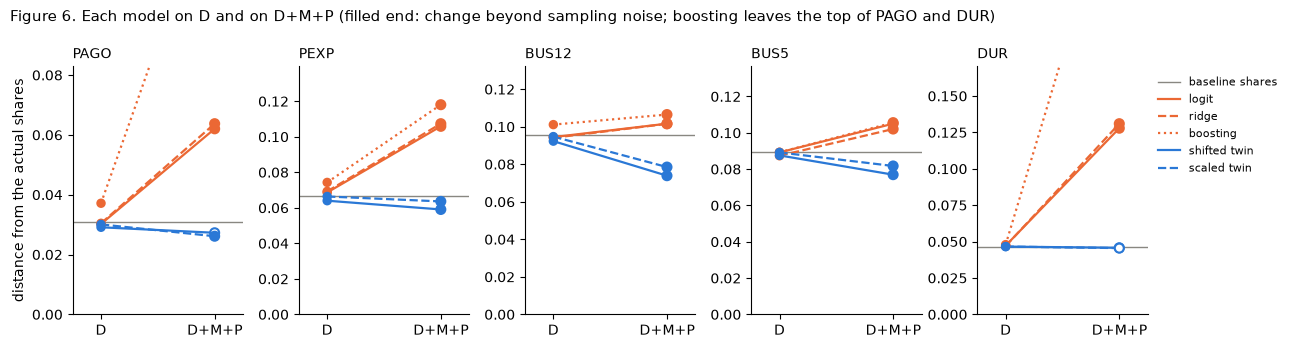

In [17]:
FAMILIES = {'mnl': 'logit', 'ridge': 'ridge', 'gb': 'boosting', 'twin_shift': 'shifted twin', 'twin_scale': 'scaled twin'}
STYLE = {'mnl': dict(color='#eb6834', ls='-'), 'ridge': dict(color='#eb6834', ls='--'), 'gb': dict(color='#eb6834', ls=':'),
         'twin_shift': dict(color='#2a78d6', ls='-'), 'twin_scale': dict(color='#2a78d6', ls='--')}
sets = ['demographics', DMP]
fig, axes = plt.subplots(1, 5, figsize=(13, 3.5))
for ax, item in zip(axes, ITEMS):
    top = 1.3 * max(allc.loc[(f'{f}_{fs}', item), 'wasserstein'] for f in FAMILIES if f != 'gb' for fs in sets)
    ax.axhline(base[item], color='#898781', lw=1, label='baseline shares')
    for f, st in STYLE.items():
        y = [allc.loc[(f'{f}_{fs}', item), 'wasserstein'] for fs in sets]
        d = cell.loc[('all', 'all', f'{f}_{DMP}-{f}_demographics', item)]
        filled = d.wasserstein_lo > 0 or d.wasserstein_hi < 0           # the change is beyond sampling noise
        ax.plot([0, 1], y, lw=1.6, label=FAMILIES[f], clip_on=True, **st)
        ax.scatter([0, 1], y, s=[28, 42], zorder=3, clip_on=True, linewidths=1.5, edgecolors=st['color'],
                   facecolors=[st['color'], st['color'] if filled else 'white'])
    ax.set_xticks([0, 1], ['D', 'D+M+P']); ax.set_xlim(-0.25, 1.25); ax.set_ylim(0, top)
    ax.set_title(item, loc='left', fontsize=10); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('distance from the actual shares')
axes[-1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 6. Each model on D and on D+M+P (filled end: change beyond sampling noise; boosting leaves the '
             'top of PAGO and DUR)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

On D, the twins and the supervised models start at nearly the same distance from the actual shares on every item, except
boosting. The state variables then pull them apart: every supervised model moves away from the actual shares on every
item, whereas the twins move toward them on three items (shifted) or four (scaled). The twins' lead on D+M+P is
therefore created by the state variables. The same move explains the twins' other two leads: on D they start level with
the supervised models on D and with the baseline shares (the grey line), so the state variables, by moving the twins
closer, put them ahead of both.

### 8.2 When: by period

Figure 7 splits the change from D by block of state variables and by period, for the logit and the shifted twin, the two
models of the primary test. A bar above zero means that the block moves the model away from the actual shares:

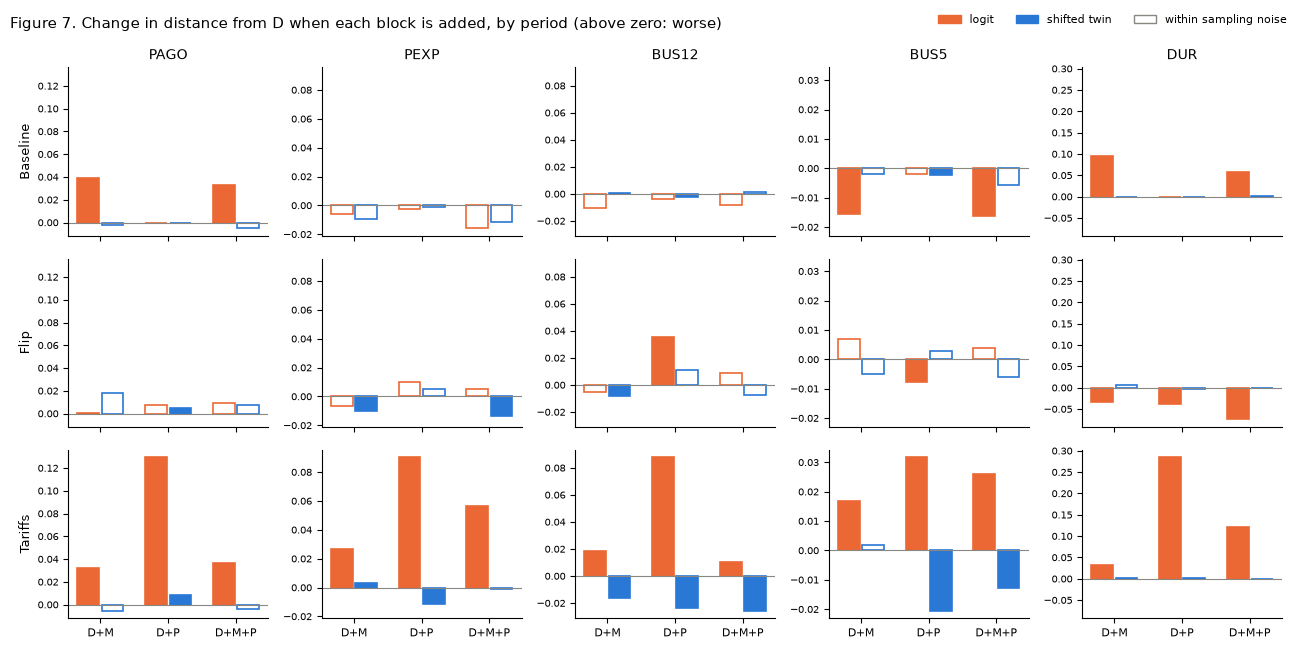

In [18]:
BLOCKS = {'D+M': 'demographics_macro', 'D+P': 'demographics_politics', 'D+M+P': DMP}
PAIR = [('mnl', '#eb6834'), ('twin_shift', '#2a78d6')]

def block_bars(rows, row_key, title):
    """Grid of rows x items: for each block, the change in distance from D of the logit and the shifted twin.
    `rows` maps a row label to the (period, group) cell it reads."""
    fig, axes = plt.subplots(len(rows), len(ITEMS), figsize=(13, 1.9 * len(rows) + 0.8), sharey='col', squeeze=False)
    for r_, (name, (p, g)) in enumerate(rows.items()):
        for c_, item in enumerate(ITEMS):
            ax = axes[r_, c_]
            for b_, fs in enumerate(BLOCKS.values()):
                for k, (f, color) in enumerate(PAIR):
                    x = cell.loc[(p, g, f'{f}_{fs}-{f}_demographics', item)]
                    filled = x.wasserstein_lo > 0 or x.wasserstein_hi < 0
                    ax.bar(b_ + (k - 0.5) * 0.36, x.wasserstein, width=0.32, color=color if filled else 'white',
                           edgecolor=color, linewidth=1.2)
            ax.axhline(0, color='#898781', lw=0.8)
            ax.set_xticks(range(len(BLOCKS)), BLOCKS if r_ == len(rows) - 1 else [''] * len(BLOCKS), fontsize=8)
            ax.tick_params(axis='y', labelsize=7); ax.spines[['top', 'right']].set_visible(False)
            if r_ == 0:
                ax.set_title(item, fontsize=10)
            if c_ == 0:
                ax.set_ylabel(name, fontsize=9)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for _, c in PAIR] + [plt.Rectangle((0, 0), 1, 1, fc='white', ec='#898781')]
    fig.legend(handles, ['logit', 'shifted twin', 'within sampling noise'], frameon=False, fontsize=8, ncol=3,
               loc='upper right', bbox_to_anchor=(1, 1.0))
    fig.suptitle(title, x=0.01, ha='left', fontsize=10.5)
    plt.tight_layout(); plt.show()

block_bars({p: (p, 'all') for p in PERIODS}, 'period',
           'Figure 7. Change in distance from D when each block is added, by period (above zero: worse)')

The divergence comes mostly from the political block, in the tariff months. There, that block worsens the logit on every
item, by more than either other block, and improves the twin on `PEXP`, `BUS12` and `BUS5`. Before the tariff months the
political block matters little for either model: in Baseline the only large effect is the logit's macro block, which
worsens `PAGO` and `DUR` as notebook 04 found, and in Flip the effects are mixed, the logit's gain on `DUR` being the
coincidence of section 5.1. The same input, a Republican president and election winner, thus moved the two models in
opposite directions. Because the political block acts through party, section 8.3 asks what it did to each party.

### 8.3 For whom: by party

The political block tells both models which party governs, and the logit also has party products, which move Republicans
and Democrats in opposite directions. Figure 8 shows what the block did to each party in the tariff months, with each
group's share of respondents in brackets:

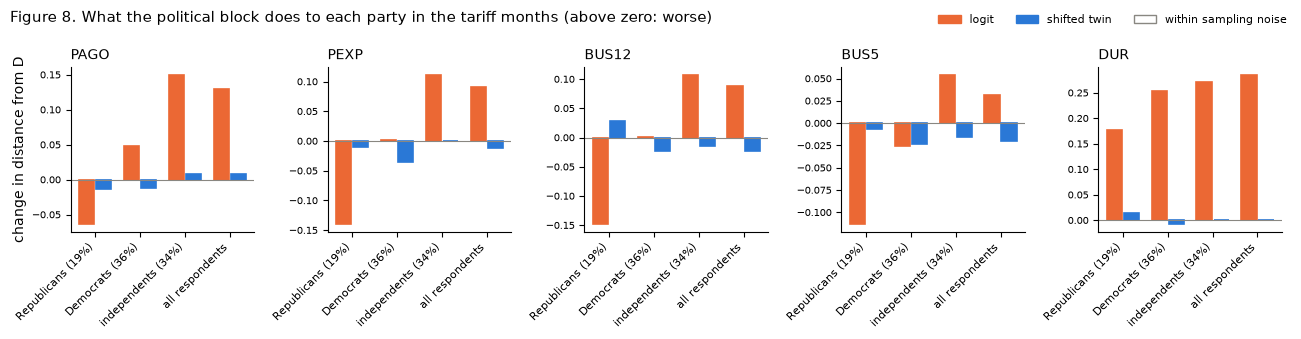

In [19]:
GROUPS = {'Rep': 'Republicans', 'Dem': 'Democrats', 'Ind': 'independents', 'all': 'all respondents'}
q = pred[(pred.YYYYMM >= PERIODS['Tariffs']) & (pred.model == LOGIT)]
w = q[q.item == 'PEXP'].groupby('party').WT.sum()
share = {g: f' ({100 * w[g] / w.sum():.0f}%)' if g in w else '' for g in GROUPS}
fig, axes = plt.subplots(1, len(ITEMS), figsize=(13, 3.4))
for ax, item in zip(axes, ITEMS):
    for x_, g in enumerate(GROUPS):
        for k, (f, color) in enumerate(PAIR):
            d = cell.loc[('Tariffs', g, f'{f}_demographics_politics-{f}_demographics', item)]
            filled = d.wasserstein_lo > 0 or d.wasserstein_hi < 0
            ax.bar(x_ + (k - 0.5) * 0.38, d.wasserstein, width=0.34, color=color if filled else 'white',
                   edgecolor=color, linewidth=1.2)
    ax.axhline(0, color='#898781', lw=0.8)
    ax.set_xticks(range(len(GROUPS)), [f'{n}{share[g]}' for g, n in GROUPS.items()], rotation=45, ha='right', fontsize=8)
    ax.tick_params(axis='y', labelsize=7); ax.spines[['top', 'right']].set_visible(False)
    ax.set_title(item, loc='left', fontsize=10)
axes[0].set_ylabel('change in distance from D')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for _, c in PAIR] + [plt.Rectangle((0, 0), 1, 1, fc='white', ec='#898781')]
fig.legend(handles, ['logit', 'shifted twin', 'within sampling noise'], frameon=False, fontsize=8, ncol=3,
           loc='upper right', bbox_to_anchor=(1, 1.0))
fig.suptitle('Figure 8. What the political block does to each party in the tariff months (above zero: worse)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

The political block helps the logit only among Republicans, and the twin mainly among Democrats. For the logit, it
improves Republicans on four items, worsens independents on every item, and has mixed effects on Democrats. For the
twin, it improves Democrats on every item and changes the other groups little. On all respondents, the logit's gain
among Republicans, 19% of respondents, is outweighed by its losses among the rest, whereas the twin's gain among
Democrats, the largest group at 36%, carries through.

Figure 9 shows why, for `PEXP` and `BUS12` in the tariff months. For each group it marks the actual net balance and
draws each model's prediction moving from D to D+P, so an arrow that points toward the actual is an improvement:

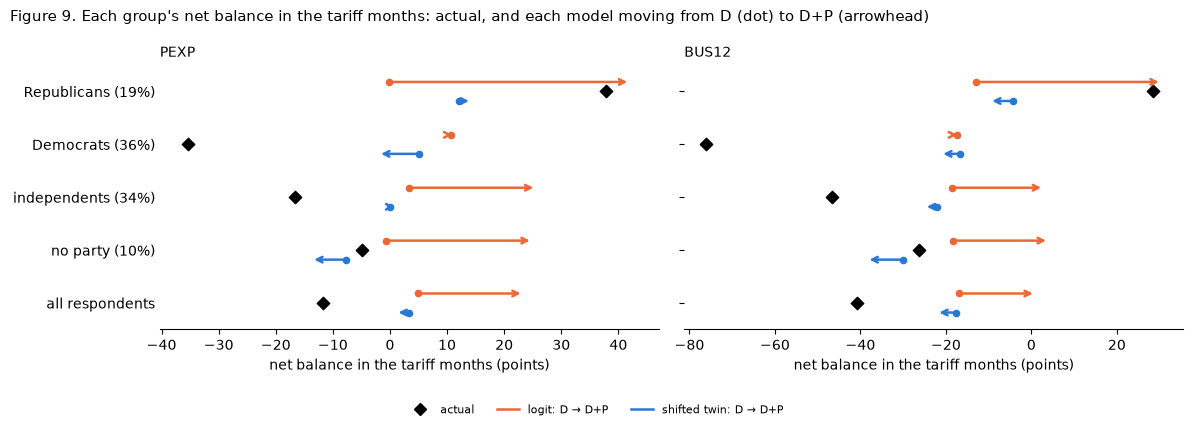

In [20]:
# Each group's net balance in the tariff months: actual, and each model's prediction on D and on D+P
PAIR_DP = {'mnl': ('logit', '#eb6834'), 'twin_shift': ('shifted twin', '#2a78d6')}
groups = {'Rep': 'Republicans', 'Dem': 'Democrats', 'Ind': 'independents', 'none': 'no party', 'all': 'all respondents'}

def level(g, m):
    """Weighted net balance of the interviews g: actual, or predicted by model m."""
    if m == 'actual':
        g = g[g.model == 'baseline']
        return 100 * np.average(g.actual_fav.astype(float) - g.actual_unf, weights=g.WT)
    g = g[g.model == m]
    return 100 * np.average(g.fav - g.unf, weights=g.WT)

tariffs = pred[pred.YYYYMM >= PERIODS['Tariffs']]
w = tariffs[(tariffs.model == LOGIT) & (tariffs.item == 'PEXP')].groupby('party').WT.sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, item in zip(axes, ['PEXP', 'BUS12']):
    q, xs = tariffs[tariffs.item == item], []
    for y, g in enumerate(groups):
        sub = q if g == 'all' else q[q.party == g]
        xs.append(level(sub, 'actual'))
        ax.scatter([xs[-1]], [y], marker='D', s=40, color='black', zorder=3)
        for k, (f, (_, color)) in enumerate(PAIR_DP.items()):
            d, dp, yy = level(sub, f'{f}_demographics'), level(sub, f'{f}_demographics_politics'), y + (k - 0.5) * 0.36
            ax.annotate('', xy=(dp, yy), xytext=(d, yy), arrowprops=dict(arrowstyle='->', color=color, lw=1.8))
            ax.scatter([d], [yy], s=20, color=color, zorder=3)
            xs += [d, dp]
    ax.set_xlim(min(xs) - 5, max(xs) + 5)        # arrows do not enter autoscaling
    ax.set_title(item, loc='left', fontsize=10); ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.set_xlabel('net balance in the tariff months (points)')
axes[0].set_yticks(range(len(groups)), [f'{n} ({100 * w[g] / w.sum():.0f}%)' if g in w else n for g, n in groups.items()])
axes[0].tick_params(axis='y', length=0); axes[0].set_ylim(len(groups) - 0.5, -0.5)
fig.suptitle('Figure 9. Each group\'s net balance in the tariff months: actual, and each model moving from D (dot) to '
             'D+P (arrowhead)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend([plt.Line2D([], [], marker='D', ls='', color='black')] +
           [plt.Line2D([], [], color=c, lw=1.8) for _, c in PAIR_DP.values()],
           ['actual'] + [f'{n}: D → D+P' for n, _ in PAIR_DP.values()], frameon=False, fontsize=8, ncol=3,
           loc='lower center')
plt.show()

The logit's political block has two parts. Its main effects raise every group by the same amount: independents and
respondents who report no party, who have no party product, move up by 21 to 26 points, away from their actual answers.
Its party products then add a further rise for Republicans and, for Democrats, a fall that cancels the common rise. The
rise is right for Republicans, whose answers lie far above the logit's prediction on D, and wrong for everyone else. The
twin's political block has no common rise: it lowers Democrats by 5 to 7 points, toward their actual answers, and moves
the other groups by at most 8 points.

The common rise is confounding (preamble). The training window holds one Republican presidency, so the logit's function
attributes to a Republican president the optimism that came with the other conditions of the first Trump presidency
(notebook 04, section 5.3), and in the tariff months it applies that optimism to every group. The twin's function comes
from general knowledge, which does not make everyone optimistic under a Republican president, so it has no such rise.
Neither function predicts the fall in answers, whose causes appear in no input, most visibly the tariffs.

## 9. Individual answers and the choice of calibration

### 9.1 Individual answers

The first table gives, for each item, the scaled twin's fitted scale a, both calibrated twins' individual skill on
D+M+P, their difference in log loss, and the supervised models that beat the scaled twin by intervals that exclude zero.
The second gives the mean individual skill over the five items, overall and by period:

In [21]:
calibration = json.load(open(TWINS / 'calibration.json'))
r = extra.loc[f'{TWIN}-{SCALED}']
display(pd.DataFrame({
    'a (scaled twin)': {i: f"{calibration['scale'][DMP][i]['a']:.2f}" for i in ITEMS},
    'skill, shifted twin': {i: f"{allc.loc[(TWIN, i), 'log_loss_skill']:+.1%}" for i in ITEMS},
    'skill, scaled twin': {i: f"{allc.loc[(SCALED, i), 'log_loss_skill']:+.1%}" for i in ITEMS},
    'shifted − scaled, log loss': {i: '{:+.3f} [{:+.3f}, {:+.3f}]'.format(
        allc.loc[(TWIN, i), 'log_loss'] - allc.loc[(SCALED, i), 'log_loss'], r.loc[i, 'log_loss_lo'], r.loc[i, 'log_loss_hi'])
        for i in ITEMS},
    'supervised models that beat the scaled twin': {i: ', '.join(
        label(s) for s in SUPERVISED_MODELS if extra.loc[(f'{SCALED}-{s}', i), 'log_loss_lo'] > 0) or '–' for i in ITEMS}}))

four = {LOGIT: 'logit', f'ridge_{DMP}': 'ridge', TWIN: 'shifted twin', SCALED: 'scaled twin'}
skill = scores[(scores.group == 'all') & scores.model.isin(four)].pivot_table(
    index='model', columns='period', values='log_loss_skill', aggfunc='mean')[['all', *PERIODS]]
all24 = [f'{f}_{fs}' for f in ['mnl', 'ridge', 'gb', 'twin', 'twin_shift', 'twin_scale'] for fs in SHORT]
print('Highest mean individual skill of the 24 models: ' + ', '.join(
    f'{m} {v:.1%}' for m, v in allc.loc[all24].log_loss_skill.groupby(level='model').mean().nlargest(3).items()))
skill.rename(index=four).loc[list(four.values())].style.format('{:+.1%}')

,a (scaled twin),"skill, shifted twin","skill, scaled twin","shifted − scaled, log loss",supervised models that beat the scaled twin
PAGO,0.46,-4.3%,+2.7%,"+0.075 [+0.068, +0.081]","mnl D+M+P, ridge D+M+P"
PEXP,0.30,-7.3%,+0.7%,"+0.090 [+0.083, +0.097]",–
BUS12,0.61,+0.5%,+1.8%,"+0.014 [+0.011, +0.016]","mnl D+M+P, ridge D+M+P, gb D+P"
BUS5,0.31,-1.1%,+2.9%,"+0.043 [+0.037, +0.050]",ridge D+M+P
DUR,0.95,+0.5%,+0.6%,"+0.000 [+0.000, +0.000]",–


Highest mean individual skill of the 24 models: twin_scale_demographics_macro_politics 1.7%, twin_scale_demographics_politics 1.4%, ridge_demographics_macro_politics 1.3%


period,all,Baseline,Flip,Tariffs
model,,,,
logit,+1.2%,+4.9%,+3.1%,+0.1%
ridge,+1.3%,+4.9%,+3.1%,+0.2%
shifted twin,-2.4%,-1.6%,-6.3%,-1.9%
scaled twin,+1.7%,+2.2%,+0.4%,+1.9%


Shrinking the twin's differences between respondents is what makes it competitive on individual answers. The shifted
twin, which keeps them, is below the baseline shares on three items, whereas the scaled twin is above them on every item
and has the highest mean skill of the 24 models. An a below 1 means that the zero-shot twin's differences in log-odds
between respondents are larger than the training web interviews support, and the gain from shrinking them is largest
where a is far below 1, on `PEXP`, `BUS5` and `PAGO`, and nil on `DUR`, where a is 0.95. Notebook 05's held-out check
anticipated the result: there the scaled twin beat the baseline shares in all 20 cells, by 0.2% to 4.5% (section 3.4).

The scaled twin does not win every item. No supervised model beats it on `PEXP` or `DUR`, the two items on which every
supervised model with state variables is below the baseline shares (Figure 4). It loses on `PAGO` and `BUS12` to the
logit and ridge on D+M+P, on `BUS12` also to boosting on D+P, and on `BUS5` to ridge. On those three items the state
variables raise the logit's individual skill most, from 2.2% to 4.1% on `PAGO`, from 0.0% to 4.3% on `BUS12` and from
1.7% to 2.7% on `BUS5` (Figure 4), consistent with its gains within parties (section 8.3).

The scaled twin's individual skill also holds up as the regime changes, whereas the logit's falls. By period, the
logit's mean skill falls from 4.9% in Baseline to 0.1% in Tariffs, whereas the scaled twin's is 2.2% in Baseline and
1.9% in Tariffs, with a dip to 0.4% in Flip, when its partisan ordering was reversed (section 5.1).

### 9.2 Shifted against scaled

The shifted twin minus the scaled twin on answer shares, and each twin's r and k from section 5.2:

In [22]:
fmt = lambda i: '{:+.4f} [{:+.4f}, {:+.4f}]'.format(allc.loc[(TWIN, i), 'wasserstein'] - allc.loc[(SCALED, i), 'wasserstein'],
                                                   r.loc[i, 'wasserstein_lo'], r.loc[i, 'wasserstein_hi'])
pd.concat([pd.DataFrame({('shifted − scaled', 'answer shares'): {i: fmt(i) for i in ITEMS}}),
           move[[NAMES[TWIN], NAMES[SCALED]]].round(2)], axis=1)

shifted − scaled shifted twin       scaled twin      
                    answer shares            r     k           r     k
PAGO   +0.0012 [-0.0014, +0.0041]         0.59  0.79        0.58  0.45
PEXP   -0.0045 [-0.0056, -0.0012]         0.73  0.25        0.73  0.10
BUS12  -0.0046 [-0.0062, -0.0031]         0.82  0.33        0.82  0.22
BUS5   -0.0048 [-0.0078, -0.0030]         0.77  0.46        0.81  0.18
DUR    +0.0002 [-0.0001, +0.0004]         0.39  0.36        0.39  0.34

The two calibrations trade one score for the other. The scaled twin is better on individual answers on every item
(section 9.1), and the shifted twin on answer shares on `PEXP`, `BUS12` and `BUS5`; on `PAGO` and `DUR` the intervals do
not separate them. The scale a causes both results, because it multiplies every difference in log-odds, between
respondents and between months alike. Between respondents, shrinking corrects the zero-shot twin's overconfidence.
Between months, it shrinks the twin's response to the state.

Shrinking the response to the state helps only where the twin moves too much. The mean squared difference between a
model's and the actual monthly net balance, each around its own mean, is σ²[(k − r)² + 1 − r²], with σ the actual's
standard deviation, so for a given r it is smallest at k = r. The shifted twin's k lies below its r on `PEXP`, `BUS12`
and `BUS5`, so shrinking moves k away from r, and above it on `PAGO` (0.79 against 0.59), so shrinking moves k toward r.

## 10. Deviations and limits

The analysis follows the plan with no deviation. Three choices the plan left open were committed in code before the
scoring run (`33be4cd`): the shared draws (`e633def`), the leave-one-out values and time sibling (`f2c54fc`, `0f6b6bc`),
and the scoring checks (`3ce725b`). The exploratory analyses listed in section 1 came after scoring, from the saved
predictions, the reason and news codes of `data/data.csv` (labelled in `data/DDI XML.txt`) and
`data/external/fred/EPUTRADE.csv` (latest vintage, 18 October 2026); the paired differences of sections 8 and 9 reuse
the scoring run's draws and reproduce its intervals.

Five limits remain. The intervals count only respondent sampling, with the months held fixed. The 19 months make up
about three episodes. Reading the survey's tax codes as tariffs is an inference. The twin's response can be split only
by block of state variables, because no prompt changed one variable at a time in the evaluation window. And the study
tests one model, one prompt and one survey.

## 11. What the study establishes

**The preregistered test is inconclusive and says little about the prediction it tests,** that the twin's relative
accuracy rises as the regime departs from training. Its dissimilarity measured only observed external conditions, fell
into three groups set by the party variables, and correlated 0.31 with how far answers moved, against 0.82 for
trade-policy uncertainty, which no input records.

**In this window, the comparisons of sections 7 to 9 support the global hypothesis.** Over 19 months that brought a
change of party and trade-policy uncertainty beyond anything in training, calibrated twins given the state came closer
to the monthly answer shares than every supervised model on every item, almost always beyond sampling noise. On
individual answers, only the scaled twins beat a constant prediction on every item.

**The two results fit as that prediction at its coarsest.** The models start level on the training web interviews, and
the twin's lead over the baseline shares, like its individual skill relative to the logit, grows from Baseline to
Tariffs. But three periods that also follow elapsed time and the events of 2025 cannot show that dissimilarity, rather
than time or those events, produced the gain.

**The state variables create the twins' lead on answer shares.** They leave the models level on D and move the
supervised models away from the actual shares and the twins toward them, mainly through the political block in the
tariff months (section 8.2). The logit moves away through confounding: its function applies to every group the optimism
that came with a Republican president in the training window, whereas the twin's function has no such rise (section
8.3). The lead thus arises as the hypothesis expects, in a regime whose observed conditions recurred without the
unobserved conditions that came with them in training, but it rests on one such episode. The twins' own gain is modest:
they remove at most 26% of the baseline shares' distance above the noise floor.

**The window says little about coverage.** Every state variable stayed inside its training range (notebook 04, section
1), and in December and January, when the election winner and the president differed in a combination absent from
training, the twin led the baseline shares by no more than in the two months before (section 5.1).

**The handicap survives calibration in differences between respondents.** b removes the twin's average error, the form's
effect included, but not its errors in differences between respondents, too strong on income and too weak on party
(notebook 05, section 5.2). Only shrinking those differences, as the scaled twin does, makes the twin competitive on
individual answers, and even then supervised models with state variables beat it on three items.

**When to use twins, on this evidence.** For a population's answer shares in a new regime, a calibrated twin given the
state predicts better than a supervised model given the same state variables, and modestly better than one without them.
Neither kind of model predicts a change that its inputs do not record, but a supervised model given the state can also
apply the effects of the training window's unobserved conditions to the new regime, as the logit did here, whereas the
twin does not. For individual answers, supervised models with the state variables predict better on three of the five
items. Of the two calibrations, the shifted twin suits answer shares and the scaled twin individual answers.

**Next tests:**

1. **Turn unobserved conditions into inputs:** give both model types a news-based measure available before each
   interview window, such as trade-policy uncertainty or a summary of the month's news, and preregister a dissimilarity
   on it.
2. **Observe more changes of regime:** rolling training and evaluation windows give more than three episodes, including
   some whose state variables leave the training range, such as the inflation of 2021 to 2022 seen from a window that
   ends in 2020; episodes before July 2024 need a model whose knowledge ends before them.
3. **Score the level shared by all respondents and the contrast between the parties separately,** because they favour
   different models.
4. **Name the incoming president in the prompt,** to test whether the twin's lag comes from the prompt or the model.